In [1]:
# Cellule 1: Imports
import numpy as np
np.set_printoptions(threshold=10000, suppress=True)
import pandas as pd
import warnings
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, precision_score, roc_curve, auc
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
warnings.filterwarnings('ignore')

In [2]:
# Charger les données - Les colonnes sont séparées par des tabulations ou espaces
# On utilise sep='\s+' pour gérer les espaces multiples, et on spécifie qu'il n'y a pas de header
df = pd.read_csv('credit.data', sep='\s+', header=None)

print("Shape du dataset:", df.shape)
print("\nPremières lignes:")
print(df.head(10))
print("\nTypes de données:")
print(df.dtypes)
print("\nNombre de valeurs manquantes ('?') par colonne:")
for i in range(df.shape[1]):
    count_missing = (df[i] == '?').sum()
    if count_missing > 0:
        print(f"Colonne {i}: {count_missing} valeurs manquantes")

Shape du dataset: (688, 16)

Premières lignes:
  0      1       2  3  4   5  6      7  8  9   10 11 12   13     14 15
0  b  30.83   0.000  u  g   w  v  1.250  t  t   1  f  g  202      0  +
1  a  58.67   4.460  u  g   q  h  3.040  t  t   6  f  g   43    560  +
2  a  24.50   0.500  u  g   q  h  1.500  t  f   0  f  g  280    824  +
3  b  27.83   1.540  u  g   w  v  3.750  t  t   5  t  g  100      3  +
4  b  20.17   5.625  u  g   w  v  1.710  t  f   0  f  s  120      0  +
5  b  32.08   4.000  u  g   m  v  2.500  t  f   0  t  g  360      0  +
6  b  33.17   1.040  u  g   r  h  6.500  t  f   0  t  g  164  31285  +
7  a  22.92  11.585  u  g  cc  v  0.040  t  f   0  f  g   80   1349  +
8  b  54.42   0.500  y  p   k  h  3.960  t  f   0  f  g  180    314  +
9  b  42.50   4.915  y  p   w  v  3.165  t  f   0  t  g   52   1442  +

Types de données:
0      object
1      object
2     float64
3      object
4      object
5      object
6      object
7     float64
8      object
9      object
10      int64

In [3]:
# Convertir en numpy array
data = df.values

# Séparer X et Y
X = data[:, :-1]  # Toutes les colonnes sauf la dernière
Y = data[:, -1]   # Dernière colonne (target)

print("Shape de X:", X.shape)
print("Shape de Y:", Y.shape)
print("\nClasses dans Y:", np.unique(Y))
print("Répartition des classes:")
unique, counts = np.unique(Y, return_counts=True)
for u, c in zip(unique, counts):
    print(f"  Classe '{u}': {c} instances ({c/len(Y)*100:.1f}%)")

Shape de X: (688, 15)
Shape de Y: (688,)

Classes dans Y: ['+' '-']
Répartition des classes:
  Classe '+': 305 instances (44.3%)
  Classe '-': 383 instances (55.7%)


In [4]:
# Convertir + en 1 et - en 0
Y_binary = np.where(Y == '+', 1, 0)

print("Target binarisée:")
print("Classe 0 (-):", np.sum(Y_binary == 0))
print("Classe 1 (+):", np.sum(Y_binary == 1))

Target binarisée:
Classe 0 (-): 383
Classe 1 (+): 305


In [5]:
# Selon la documentation UCI:
# Colonnes numériques (indices): 1, 2, 7, 10, 13, 14
# Colonnes catégorielles (indices): 0, 3, 4, 5, 6, 8, 9, 11, 12

col_num = [1, 2, 7, 10, 13, 14]
col_cat = [0, 3, 4, 5, 6, 8, 9, 11, 12]

print("Colonnes numériques:", col_num)
print("Colonnes catégorielles:", col_cat)

Colonnes numériques: [1, 2, 7, 10, 13, 14]
Colonnes catégorielles: [0, 3, 4, 5, 6, 8, 9, 11, 12]


In [6]:
# Copier les colonnes catégorielles
X_cat = np.copy(X[:, col_cat])

print("Shape des données catégorielles:", X_cat.shape)
print("\nExemple de données catégorielles avant transformation:")
print(X_cat[:5])

# Transformer les valeurs catégorielles en valeurs numériques
for col_id in range(len(col_cat)):
    unique_val, val_idx = np.unique(X_cat[:, col_id], return_inverse=True)
    X_cat[:, col_id] = val_idx
    print(f"\nColonne {col_cat[col_id]}: {len(unique_val)} modalités uniques")

print("\nDonnées catégorielles après transformation:")
print(X_cat[:5])

Shape des données catégorielles: (688, 9)

Exemple de données catégorielles avant transformation:
[['b' 'u' 'g' 'w' 'v' 't' 't' 'f' 'g']
 ['a' 'u' 'g' 'q' 'h' 't' 't' 'f' 'g']
 ['a' 'u' 'g' 'q' 'h' 't' 'f' 'f' 'g']
 ['b' 'u' 'g' 'w' 'v' 't' 't' 't' 'g']
 ['b' 'u' 'g' 'w' 'v' 't' 'f' 'f' 's']]

Colonne 0: 3 modalités uniques

Colonne 3: 4 modalités uniques

Colonne 4: 4 modalités uniques

Colonne 5: 15 modalités uniques

Colonne 6: 10 modalités uniques

Colonne 8: 2 modalités uniques

Colonne 9: 2 modalités uniques

Colonne 11: 2 modalités uniques

Colonne 12: 3 modalités uniques

Données catégorielles après transformation:
[[2 2 1 13 8 1 1 0 0]
 [1 2 1 11 4 1 1 0 0]
 [1 2 1 11 4 1 0 0 0]
 [2 2 1 13 8 1 1 1 0]
 [2 2 1 13 8 1 0 0 2]]


In [7]:
# Remplacer '0' qui correspond à '?' par la valeur la plus fréquente
# Note: après unique(), '?' devient souvent la valeur 0
X_cat = X_cat.astype(float)

# Imputer avec la stratégie most_frequent
imp_cat = SimpleImputer(missing_values=0, strategy='most_frequent')
X_cat = imp_cat.fit_transform(X_cat)

print("Valeurs manquantes dans X_cat après imputation:", np.sum(np.isnan(X_cat)))
print("\nDonnées catégorielles après imputation:")
print(X_cat[:5])

Valeurs manquantes dans X_cat après imputation: 0

Données catégorielles après imputation:
[[ 2.  2.  1. 13.  8.  1.  1.  1.  2.]
 [ 1.  2.  1. 11.  4.  1.  1.  1.  2.]
 [ 1.  2.  1. 11.  4.  1.  1.  1.  2.]
 [ 2.  2.  1. 13.  8.  1.  1.  1.  2.]
 [ 2.  2.  1. 13.  8.  1.  1.  1.  2.]]


In [8]:
# Copier les colonnes numériques
X_num = np.copy(X[:, col_num])

print("Shape des données numériques:", X_num.shape)
print("\nExemple de données numériques avant transformation:")
print(X_num[:5])

# Remplacer '?' par nan
X_num[X_num == '?'] = np.nan
X_num = X_num.astype(float)

print("\nNombre de valeurs manquantes par colonne numérique:")
for i in range(X_num.shape[1]):
    count_nan = np.sum(np.isnan(X_num[:, i]))
    print(f"Colonne {col_num[i]}: {count_nan} NaN")

Shape des données numériques: (688, 6)

Exemple de données numériques avant transformation:
[['30.83' 0.0 1.25 1 '202' 0]
 ['58.67' 4.46 3.04 6 '43' 560]
 ['24.50' 0.5 1.5 0 '280' 824]
 ['27.83' 1.54 3.75 5 '100' 3]
 ['20.17' 5.625 1.71 0 '120' 0]]

Nombre de valeurs manquantes par colonne numérique:
Colonne 1: 12 NaN
Colonne 2: 0 NaN
Colonne 7: 0 NaN
Colonne 10: 0 NaN
Colonne 13: 11 NaN
Colonne 14: 0 NaN


In [9]:

# Imputer avec la moyenne
imp_num = SimpleImputer(missing_values=np.nan, strategy='mean')
X_num = imp_num.fit_transform(X_num)

print("Valeurs manquantes dans X_num après imputation:", np.sum(np.isnan(X_num)))
print("\nDonnées numériques après imputation:")
print(X_num[:5])
print("\nStatistiques des variables numériques:")
print("Moyennes:", np.mean(X_num, axis=0))
print("Écarts-types:", np.std(X_num, axis=0))

Valeurs manquantes dans X_num après imputation: 0

Données numériques après imputation:
[[ 30.83    0.      1.25    1.    202.      0.   ]
 [ 58.67    4.46    3.04    6.     43.    560.   ]
 [ 24.5     0.5     1.5     0.    280.    824.   ]
 [ 27.83    1.54    3.75    5.    100.      3.   ]
 [ 20.17    5.625   1.71    0.    120.      0.   ]]

Statistiques des variables numériques:
Moyennes: [  31.5189497     4.76856105    2.22659884    2.39825581  184.01477105
 1019.47093023]
Écarts-types: [  11.760483      4.97787639    3.34786991    4.86367616  172.28434385
 5213.71865786]


In [10]:
# Encoder les variables catégorielles en variables binaires
encoder = OneHotEncoder(sparse_output=False)
X_cat_bin = encoder.fit_transform(X_cat)

print("Shape après One-Hot Encoding:", X_cat_bin.shape)
print("Nombre de features catégorielles binaires créées:", X_cat_bin.shape[1])
print("\nExemple de données après One-Hot Encoding:")
print(X_cat_bin[:5, :10])  # Afficher les 10 premières colonnes

Shape après One-Hot Encoding: (688, 36)
Nombre de features catégorielles binaires créées: 36

Exemple de données après One-Hot Encoding:
[[0. 1. 0. 1. 0. 1. 0. 0. 0. 0.]
 [1. 0. 0. 1. 0. 1. 0. 0. 0. 0.]
 [1. 0. 0. 1. 0. 1. 0. 0. 0. 0.]
 [0. 1. 0. 1. 0. 1. 0. 0. 0. 0.]
 [0. 1. 0. 1. 0. 1. 0. 0. 0. 0.]]


In [11]:
# Normaliser les variables continues
scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(X_num)

print("Données numériques après normalisation:")
print("Moyennes:", np.mean(X_num_scaled, axis=0))
print("Écarts-types:", np.std(X_num_scaled, axis=0))
print("\nExemple de données normalisées:")
print(X_num_scaled[:5])

Données numériques après normalisation:
Moyennes: [-0.  0.  0. -0.  0.  0.]
Écarts-types: [1. 1. 1. 1. 1. 1.]

Exemple de données normalisées:
[[-0.05858175 -0.95795088 -0.29170752 -0.2874895   0.10439271 -0.19553624]
 [ 2.30866796 -0.06198648  0.2429608   0.74053947 -0.81850021 -0.0881273 ]
 [-0.59682495 -0.85750644 -0.21703318 -0.49309529  0.55713263 -0.03749165]
 [-0.31367332 -0.648582    0.45503595  0.53493368 -0.4876518  -0.19496083]
 [-0.96500711  0.17204906 -0.15430672 -0.49309529 -0.37156464 -0.19553624]]


In [12]:
# Concaténer les données catégorielles encodées et les données numériques normalisées
X_final = np.concatenate([X_cat_bin, X_num_scaled], axis=1)

print("Shape du jeu de données final:", X_final.shape)
print("Nombre total de features:", X_final.shape[1])
print("  - Features catégorielles (binaires):", X_cat_bin.shape[1])
print("  - Features numériques (normalisées):", X_num_scaled.shape[1])

Shape du jeu de données final: (688, 42)
Nombre total de features: 42
  - Features catégorielles (binaires): 36
  - Features numériques (normalisées): 6


In [13]:
# ============================================================================
# Cellule 13: Séparation train/test
# ============================================================================

X_train, X_test, Y_train, Y_test = train_test_split(
    X_final, Y_binary, test_size=0.5, random_state=1
)

print("\nSéparation train/test:")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Y_train - Classe 0:", np.sum(Y_train == 0), "| Classe 1:", np.sum(Y_train == 1))
print("Y_test - Classe 0:", np.sum(Y_test == 0), "| Classe 1:", np.sum(Y_test == 1))


Séparation train/test:
X_train shape: (344, 42)
X_test shape: (344, 42)
Y_train - Classe 0: 183 | Classe 1: 161
Y_test - Classe 0: 200 | Classe 1: 144


In [14]:

# ============================================================================
# Cellule 14: Fonction d'évaluation
# ============================================================================

def evaluate_model(y_true, y_pred, y_proba, model_name):
    """
    Évalue un modèle et affiche les métriques
    """
    # Matrice de confusion
    cm = confusion_matrix(y_true, y_pred)
    
    # Métriques
    acc = accuracy_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    
    # Pour le crédit scoring, le rappel est plus important (détecter les défauts)
    best_metric = recall
    final_score = (acc + best_metric) / 2
    
    # Courbe ROC et AUC
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    roc_auc = auc(fpr, tpr)
    
    # Affichage
    print(f"\n{'='*60}")
    print(f"Résultats pour: {model_name}")
    print(f"{'='*60}")
    print(f"Matrice de confusion:")
    print(cm)
    print(f"\nAccuracy: {acc:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"AUC: {roc_auc:.4f}")
    print(f"Score final (Accuracy + Recall)/2: {final_score:.4f}")
    
    # Graphique ROC
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, 
             label=f'ROC curve (AUC = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve - {model_name}')
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()
    
    return final_score, roc_auc


In [15]:
# ============================================================================
# Cellule 15: Fonction run_classifiers
# ============================================================================

def run_classifiers(X_train, X_test, Y_train, Y_test, classifiers_dict):
    """
    Entraîne et évalue plusieurs classifieurs
    """
    results = {}
    
    for name, clf in classifiers_dict.items():
        print(f"\n\nEntraînement de {name}...")
        
        # Entraînement
        clf.fit(X_train, Y_train)
        
        # Prédictions
        y_pred = clf.predict(X_test)
        y_proba = clf.predict_proba(X_test)[:, 1]
        
        # Évaluation
        score, roc_auc = evaluate_model(Y_test, y_pred, y_proba, name)
        
        results[name] = {
            'model': clf,
            'score': score,
            'auc': roc_auc
        }
    
    # Meilleur modèle
    best_model_name = max(results, key=lambda x: results[x]['score'])
    print(f"\n\n{'='*60}")
    print(f"MEILLEUR MODÈLE: {best_model_name}")
    print(f"Score final: {results[best_model_name]['score']:.4f}")
    print(f"AUC: {results[best_model_name]['auc']:.4f}")
    print(f"{'='*60}")
    
    return results, results[best_model_name]['model']

ÉVALUATION SUR DONNÉES COMPLÈTES (catégorielles + numériques)


Entraînement de CART...

Résultats pour: CART
Matrice de confusion:
[[143  57]
 [ 43 101]]

Accuracy: 0.7093
Recall: 0.7014
Precision: 0.6392
AUC: 0.7082
Score final (Accuracy + Recall)/2: 0.7053


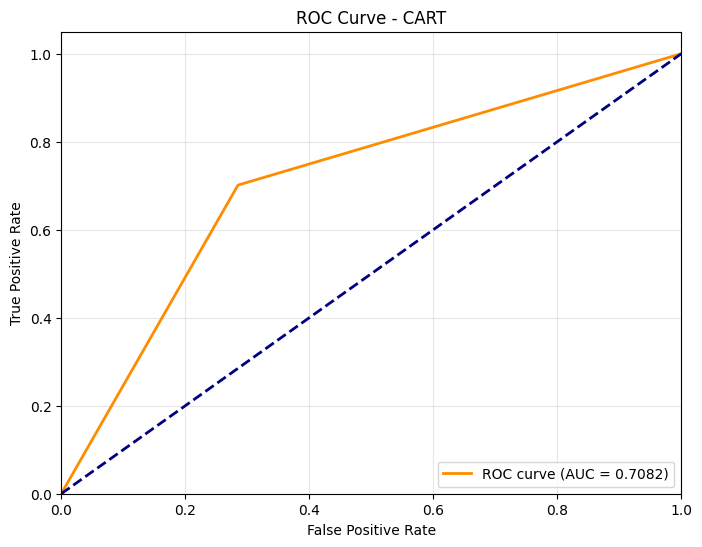



Entraînement de KNN-5...

Résultats pour: KNN-5
Matrice de confusion:
[[171  29]
 [ 56  88]]

Accuracy: 0.7529
Recall: 0.6111
Precision: 0.7521
AUC: 0.8222
Score final (Accuracy + Recall)/2: 0.6820


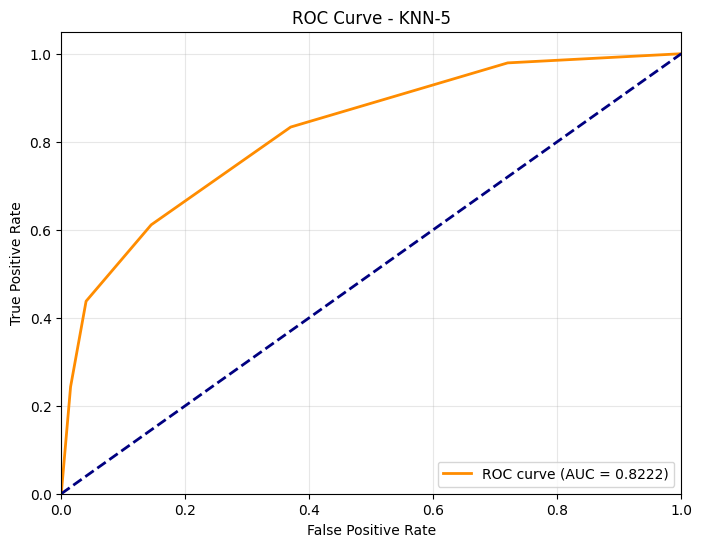



Entraînement de MLP...

Résultats pour: MLP
Matrice de confusion:
[[156  44]
 [ 37 107]]

Accuracy: 0.7645
Recall: 0.7431
Precision: 0.7086
AUC: 0.8297
Score final (Accuracy + Recall)/2: 0.7538


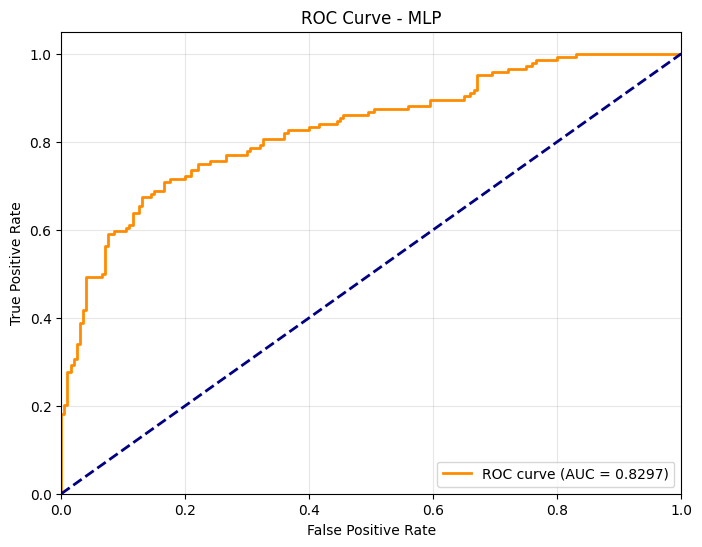



MEILLEUR MODÈLE: MLP
Score final: 0.7538
AUC: 0.8297


In [16]:
# Cellule 16: Exécution sur les données préparées
# ============================================================================

# Définir les classifieurs
classifiers = {
    'CART': DecisionTreeClassifier(random_state=1),
    'KNN-5': KNeighborsClassifier(n_neighbors=5),
    'MLP': MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1, max_iter=500)
}

print("ÉVALUATION SUR DONNÉES COMPLÈTES (catégorielles + numériques)")
print("="*60)

results, best_model = run_classifiers(X_train, X_test, Y_train, Y_test, classifiers)


In [17]:
# ============================================================================
# Cellule 17: Résumé des résultats
# ============================================================================

print("\n\nRÉSUMÉ DES RÉSULTATS")
print("="*60)
print(f"{'Modèle':<15} {'Score Final':<15} {'AUC':<10}")
print("-"*60)
for name, res in results.items():
    print(f"{name:<15} {res['score']:<15.4f} {res['auc']:<10.4f}")

print("\n\nCONCLUSION:")
print("-"*60)
print(f"• Nombre total d'instances: {len(X_final)}")
print(f"• Nombre de features finales: {X_final.shape[1]}")
print(f"  - Variables catégorielles encodées: {X_cat_bin.shape[1]}")
print(f"  - Variables numériques normalisées: {X_num_scaled.shape[1]}")
print(f"• Données manquantes: traitées par imputation")
print(f"• Meilleur modèle: {max(results, key=lambda x: results[x]['score'])}")



RÉSUMÉ DES RÉSULTATS
Modèle          Score Final     AUC       
------------------------------------------------------------
CART            0.7053          0.7082    
KNN-5           0.6820          0.8222    
MLP             0.7538          0.8297    


CONCLUSION:
------------------------------------------------------------
• Nombre total d'instances: 688
• Nombre de features finales: 42
  - Variables catégorielles encodées: 36
  - Variables numériques normalisées: 6
• Données manquantes: traitées par imputation
• Meilleur modèle: MLP
